# ReadmitIQ Stage 6: Model Evaluation, Explainability, Fairness & Drift
> **One-Line Promise**: Rigorously benchmarking the six-model evaluation grid on validation data, dissecting predictive mechanisms via Tree SHAP and permutation importance, auditing algorithmic fairness across demographic subgroups, tracking feature drift, and presenting governance-locked test metrics.

---

### What This Stage Covers
From the ReadmitIQ clinical specification, Stage 6 delivers the culminating scientific evaluation and ethical governance for hospital readmission risk prediction:
1. **The Six-Model Comparison Grid**: Comprehensive benchmarking across Logistic Regression, Random Forest, and Transformer architectures (each evaluated with and without RAG features), plus LightGBM configurations labeled "extra" on the full $N=14,902$ validation split.
2. **Paired Bootstrap Differences & Forest Plot**: Non-parametric paired bootstrap difference distributions for RAG augmentations ($\Delta \text{AUC}$) with 95% confidence intervals and an honest plain-language clinical verdict.
3. **Global Model Interpretability (Tree SHAP & Permutation)**: Computing exact game-theoretic Shapley attributions across all 14,902 validation encounters, ranking features by clinical impact, and validating predictive reliance through permutation importance.
4. **Local Patient Explainability & Clinical Waterfalls**: Decomposing individual patient risk scores into positive and negative clinical drivers, translating raw log-odds contributions into plain-language clinical rationales, and auditing explanation reliability.
5. **Algorithmic Fairness & Subgroup Disparity Audit**: Evaluating demographic parity, equalized odds, and disparate impact ratios across protected racial and gender subgroups, with strict programmatic enforcement ensuring group selection rates never exceed safe operational limits ($<0.50$).
6. **Population Stability Index (PSI) & Feature Drift Monitoring**: Longitudinal distributional stability analysis across training, validation, and test cohorts across all 42 clinical features to establish drift monitoring baselines.
7. **Governance-Locked Test Summary (Read-Only)**: Reviewing the frozen final model evaluation on the independent test set ($N=14,903$), evaluated once under cryptographic lock and presented strictly read-only with zero data snooping.
8. **Computed Stage Checklist**: Programmatic verification of grid completeness, SHAP attributions, fairness safety thresholds, drift stability, and slide-ready figure artifacts.
9. **Next Stage Pointer**: Handover to Stage 7 (Production Deployment and ActionLoop Clinical Workflow).

---

### Inputs and Outputs of Stage 6
- **Inputs Read (Existing Artifacts)**:
  - `data/processed/val_rag.parquet` (Validation cohort with structured RAG features; 14,902 rows)
  - `models/final/model.joblib` (Frozen primary LightGBM ensemble)
  - `models/final/calibrator.joblib` (Isotonic regression probability calibrator)
  - `models/final/feature_list.json` (42 feature names and types)
  - `reports/metrics/ablation_table.json` (Validation performance metrics and paired bootstrap distributions)
  - `reports/metrics/sample_explanations.json` (Pre-audited patient cases with local SHAP attributions)
  - `reports/metrics/fairness_audit.json` (Demographic subgroup fairness metrics across race and gender)
  - `reports/metrics/drift_metrics.json` (PSI population stability metrics for all 42 features)
  - `reports/metrics/test_results.json` & `reports/metrics/test_eval.lock` (Governance-locked test results)
  - `reports/colab_outputs/distilbert_val_predictions_notes.csv` (Out-of-sample validation predictions for DistilBERT)
- **Outputs Produced (New Artifacts Strictly Confined)**:
  - `reports/stages/figures/stage6_forest_plot.png` (Forest plot of paired $\Delta\text{AUC}$ with 95% CIs)
  - `reports/stages/figures/stage6_shap_summary.png` (Global Tree SHAP mean absolute attribution bar chart)
  - `reports/stages/figures/stage6_permutation_importance.png` (Validation permutation importance drop)
  - `reports/stages/figures/stage6_local_waterfalls.png` (Patient-level local risk waterfall attributions)
  - `reports/stages/figures/stage6_fairness_disparity.png` (Subgroup AUC and selection rate fairness audit)
  - `reports/stages/figures/stage6_psi_drift.png` (Feature Population Stability Index drift comparison)
  - `reports/stages/stage6.html` (Exported standalone HTML report)

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

# Centralized repository root resolution (robust across any execution working directory)
curr = Path.cwd().resolve()
while curr != curr.parent and not (curr / "src").exists():
    curr = curr.parent
REPO_ROOT = curr
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display
from sklearn.exceptions import InconsistentVersionWarning
from sklearn.metrics import brier_score_loss

# Suppress benign unpickling version warnings across scikit-learn 1.9.0 vs 1.9.1 and matplotlib ticklabel warnings
warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
warnings.filterwarnings("ignore", category=UserWarning)
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

from notebooks.stages._stage_helpers import (
    set_stage_style,
    save_stage_figure,
    render_pending_box,
    rel_path,
    evaluate_stage_checklist,
    STAGE_PALETTE,
    annotate_bars,
    compute_roc_auc
)
from src.explain import ModelExplainer, generate_plain_english_summary, check_explanation_reliability, format_clinical_reason

set_stage_style()
print("Stage 6 execution environment initialized successfully.")
print(f"Repository Root: {rel_path(REPO_ROOT)}")


Stage 6 execution environment initialized successfully.
Repository Root: .


## 1. Ingesting Validation Data & Governance Artifacts
We load the validated reference cohort (`val_rag.parquet`), the frozen final LightGBM model, and the audited evaluation metrics. In strict accordance with clinical research governance, the independent **test set is off-limits** for any new model training, parameter tuning, or metric recomputation.

In [2]:
# Ingest validation dataset and governance artifacts
import warnings
from sklearn.exceptions import InconsistentVersionWarning
warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
warnings.filterwarnings("ignore", category=UserWarning)

val_df = pd.read_parquet(REPO_ROOT / "data" / "processed" / "val_rag.parquet")
y_val = val_df["readmitted_30d"].to_numpy()

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=InconsistentVersionWarning)
    final_model = joblib.load(REPO_ROOT / "models" / "final" / "model.joblib")

with open(REPO_ROOT / "models" / "final" / "feature_list.json", "r", encoding="utf-8") as f:
    feat_meta = json.load(f)

num_cols = feat_meta["numeric_features"]
cat_cols = feat_meta["categorical_features"]
all_cols = feat_meta["all_features"]

with open(REPO_ROOT / "reports" / "metrics" / "ablation_table.json", "r", encoding="utf-8") as f:
    ablation_data = json.load(f)

with open(REPO_ROOT / "reports" / "metrics" / "fairness_audit.json", "r", encoding="utf-8") as f:
    fairness_data = json.load(f)

with open(REPO_ROOT / "reports" / "metrics" / "drift_metrics.json", "r", encoding="utf-8") as f:
    drift_data = json.load(f)

with open(REPO_ROOT / "reports" / "metrics" / "sample_explanations.json", "r", encoding="utf-8") as f:
    sample_exps = json.load(f)

distilbert_val_path = REPO_ROOT / "reports" / "colab_outputs" / "distilbert_val_predictions_notes.csv"
if not distilbert_val_path.exists():
    distilbert_val_path = REPO_ROOT / "reports" / "colab" / "distilbert_val_predictions_notes.csv"
distilbert_val_df = pd.read_csv(distilbert_val_path) if distilbert_val_path.exists() else None

distilbert_noterag_val_path = REPO_ROOT / "reports" / "note_rag" / "colab" / "distilbert_val_predictions_notes_noterag.csv"
if not distilbert_noterag_val_path.exists():
    distilbert_noterag_val_path = REPO_ROOT / "reports" / "colab_outputs" / "distilbert_val_predictions_notes_rag.csv"
distilbert_noterag_val_df = pd.read_csv(distilbert_noterag_val_path) if distilbert_noterag_val_path.exists() else None

print(f"Loaded Validation Cohort: {len(val_df):,} encounters, {len(all_cols)} features (Prevalence: {y_val.mean()*100:.2f}%)")
print(f"Loaded Final LightGBM Model: {final_model.__class__.__name__} with {len(all_cols)} input dimensions")
print(f"Loaded Ablation Table: {len(ablation_data['ablation_results'])} tabular baseline configurations")
print(f"Loaded Sample Explanations: {len(sample_exps)} audited clinical cases")
if distilbert_val_df is not None:
    print(f"Loaded DistilBERT Validation Predictions: {len(distilbert_val_df):,} rows")
if distilbert_noterag_val_df is not None:
    print(f"Loaded DistilBERT + Note-RAG Validation Predictions: {len(distilbert_noterag_val_df):,} rows")


Loaded Validation Cohort: 14,902 encounters, 42 features (Prevalence: 11.39%)
Loaded Final LightGBM Model: LGBMClassifier with 42 input dimensions
Loaded Ablation Table: 6 tabular baseline configurations
Loaded Sample Explanations: 5 audited clinical cases
Loaded DistilBERT Validation Predictions: 14,902 rows
Loaded DistilBERT + Note-RAG Validation Predictions: 14,902 rows


## 2. The Six-Model Comparison Grid (Validation Split $N=14,902$)
The ReadmitIQ specification mandates side-by-side benchmarking across six core model configurations (Logistic Regression, Random Forest, and Transformer, each with and without RAG) plus high-capacity LightGBM configurations labeled "extra".

All models including DistilBERT (without RAG and with Note-RAG) have been trained and evaluated across the complete 14,902 validation encounters under identical experimental conditions without subsampling.


In [3]:
# Construct the Six-Model Comparison Grid
grid_rows = []

# 1 & 2: Logistic Regression
for res in ablation_data["ablation_results"]:
    if res["model"] == "Logistic Regression":
        rag_label = "With RAG" if res["rag_feature"] else "Without RAG"
        grid_rows.append({
            "Architecture": "Logistic Regression",
            "Configuration": rag_label,
            "Role": "Baseline Model",
            "Status": "Evaluated",
            "AUC-ROC": f"{res['auc_roc']:.4f}",
            "95% CI": f"[{res['auc_ci_95'][0]:.4f}, {res['auc_ci_95'][1]:.4f}]",
            "F1-Score": f"{res['f1']:.4f}",
            "Prec@10%": f"{res['precision_top_10pct']*100:.2f}%",
            "Lift@10%": f"{res['lift_top_10pct']:.2f}x",
            "Brier Score": f"{res['brier_score']:.4f}",
            "ECE": f"{res['ece']:.4f}",
        })

# 3 & 4: Random Forest
for res in ablation_data["ablation_results"]:
    if res["model"] == "Random Forest":
        rag_label = "With RAG" if res["rag_feature"] else "Without RAG"
        grid_rows.append({
            "Architecture": "Random Forest",
            "Configuration": rag_label,
            "Role": "Baseline Model",
            "Status": "Evaluated",
            "AUC-ROC": f"{res['auc_roc']:.4f}",
            "95% CI": f"[{res['auc_ci_95'][0]:.4f}, {res['auc_ci_95'][1]:.4f}]",
            "F1-Score": f"{res['f1']:.4f}",
            "Prec@10%": f"{res['precision_top_10pct']*100:.2f}%",
            "Lift@10%": f"{res['lift_top_10pct']:.2f}x",
            "Brier Score": f"{res['brier_score']:.4f}",
            "ECE": f"{res['ece']:.4f}",
        })

# 5: Transformer (Without RAG)
p_db = distilbert_val_df["prob"].to_numpy()
y_db = distilbert_val_df["readmitted_30d"].to_numpy()
from src.evaluate import evaluate_predictions
db_m = evaluate_predictions(y_db, p_db, n_bootstraps=500, seed=42)

top10_k = int(len(p_db) * 0.10)
top10_idx = np.argsort(p_db)[::-1][:top10_k]
prec_top10_db = y_db[top10_idx].mean()
base_prev = y_db.mean()
lift_top10_db = prec_top10_db / base_prev
brier_db = brier_score_loss(y_db, p_db)

grid_rows.append({
    "Architecture": "Transformer (DistilBERT)",
    "Configuration": "Without RAG",
    "Role": "Deep Language Model",
    "Status": "Evaluated",
    "AUC-ROC": f"{db_m['auc_roc']:.4f}",
    "95% CI": f"[{db_m['auc_ci_95'][0]:.4f}, {db_m['auc_ci_95'][1]:.4f}]",
    "F1-Score": f"{db_m['f1']:.4f}",
    "Prec@10%": f"{prec_top10_db*100:.2f}%",
    "Lift@10%": f"{lift_top10_db:.2f}x",
    "Brier Score": f"{brier_db:.4f}",
    "ECE": f"{db_m['ece']:.4f}",
})

# 6: Transformer (With Note-RAG)
if distilbert_noterag_val_df is not None:
    p_rag = distilbert_noterag_val_df["prob"].to_numpy()
    y_rag = distilbert_noterag_val_df["readmitted_30d"].to_numpy()
    db_rag_m = evaluate_predictions(y_rag, p_rag, n_bootstraps=500, seed=42)
    
    top10_k_rag = int(len(p_rag) * 0.10)
    top10_idx_rag = np.argsort(p_rag)[::-1][:top10_k_rag]
    prec_top10_rag = y_rag[top10_idx_rag].mean()
    lift_top10_rag = prec_top10_rag / base_prev
    brier_rag = brier_score_loss(y_rag, p_rag)
    
    grid_rows.append({
        "Architecture": "Transformer (DistilBERT)",
        "Configuration": "With Note-RAG",
        "Role": "Deep Language Model",
        "Status": "Evaluated",
        "AUC-ROC": f"{db_rag_m['auc_roc']:.4f}",
        "95% CI": f"[{db_rag_m['auc_ci_95'][0]:.4f}, {db_rag_m['auc_ci_95'][1]:.4f}]",
        "F1-Score": f"{db_rag_m['f1']:.4f}",
        "Prec@10%": f"{prec_top10_rag*100:.2f}%",
        "Lift@10%": f"{lift_top10_rag:.2f}x",
        "Brier Score": f"{brier_rag:.4f}",
        "ECE": f"{db_rag_m['ece']:.4f}",
    })

# 7 & 8: LightGBM (Extra / Primary Candidate)
for res in ablation_data["ablation_results"]:
    if res["model"] == "LightGBM":
        rag_label = "With Structured RAG (Primary)" if res["rag_feature"] else "Without RAG"
        role_label = "[EXTRA / PRIMARY]" if res["rag_feature"] else "[EXTRA]"
        grid_rows.append({
            "Architecture": "LightGBM",
            "Configuration": rag_label,
            "Role": role_label,
            "Status": "Evaluated",
            "AUC-ROC": f"{res['auc_roc']:.4f}",
            "95% CI": f"[{res['auc_ci_95'][0]:.4f}, {res['auc_ci_95'][1]:.4f}]",
            "F1-Score": f"{res['f1']:.4f}",
            "Prec@10%": f"{res['precision_top_10pct']*100:.2f}%",
            "Lift@10%": f"{res['lift_top_10pct']:.2f}x",
            "Brier Score": f"{res['brier_score']:.4f}",
            "ECE": f"{res['ece']:.4f}",
        })

grid_df = pd.DataFrame(grid_rows)
display(grid_df)


,Architecture,Configuration,Role,Status,AUC-ROC,95% CI,F1-Score,Prec@10%,Lift@10%,Brier Score,ECE
0,Logistic Regression,Without RAG,Baseline Model,Evaluated,0.6619,"[0.6484, 0.6757]",0.2770,23.76%,2.09x,0.2291,0.3557
1,Logistic Regression,With RAG,Baseline Model,Evaluated,0.6632,"[0.6501, 0.6772]",0.2766,24.30%,2.13x,0.2287,0.3554
2,Random Forest,Without RAG,Baseline Model,Evaluated,0.6671,"[0.6547, 0.6804]",0.2795,24.03%,2.11x,0.2112,0.3348
3,Random Forest,With RAG,Baseline Model,Evaluated,0.6674,"[0.6548, 0.6806]",0.2778,25.10%,2.20x,0.2096,0.3325
4,Transformer (DistilBERT),Without RAG,Deep Language Model,Evaluated,0.6497,"[0.6369, 0.6623]",0.2708,23.69%,2.08x,0.2058,0.3145
5,Transformer (DistilBERT),With Note-RAG,Deep Language Model,Evaluated,0.6491,"[0.6357, 0.6634]",0.2662,23.89%,2.10x,0.2106,0.3206
6,LightGBM,Without RAG,[EXTRA],Evaluated,0.6722,"[0.6593, 0.6854]",0.2819,25.57%,2.25x,0.2196,0.3425
7,LightGBM,With Structured RAG (Primary),[EXTRA / PRIMARY],Evaluated,0.6731,"[0.6602, 0.6863]",0.2822,25.30%,2.22x,0.2194,0.3420


In [4]:
# Summary of Six-Model Grid Evaluation
evaluated_count = sum(r["Status"] == "Evaluated" for r in grid_rows)
print(f"[VERIFIED] Six-Model Comparison Grid: All {evaluated_count} configurations successfully evaluated.")
print(f"  - Baseline Models (LR, RF): Completed with and without RAG")
print(f"  - Deep Language Models (DistilBERT): Completed with and without Note-RAG on full {len(y_val):,} validation encounters")
print(f"  - Production Primary (LightGBM): Completed with and without Structured RAG")


[VERIFIED] Six-Model Comparison Grid: All 8 configurations successfully evaluated.
  - Baseline Models (LR, RF): Completed with and without RAG
  - Deep Language Models (DistilBERT): Completed with and without Note-RAG on full 14,902 validation encounters
  - Production Primary (LightGBM): Completed with and without Structured RAG


## 3. Paired Bootstrap Differences & Forest Plot
To determine whether RAG retrieval statistically elevates discrimination, we analyze paired bootstrap difference distributions ($B=1,000$ resamples) where each bootstrap draw evaluates the exact difference:
$$\Delta \text{AUC} = \text{AUC}_{\text{Model+RAG}} - \text{AUC}_{\text{Model Base}}$$

If the 95% bootstrap confidence interval crosses zero, the gain cannot be deemed statistically significant at $\alpha=0.05$.

Saved figure: reports/stages/figures/stage6_forest_plot.png


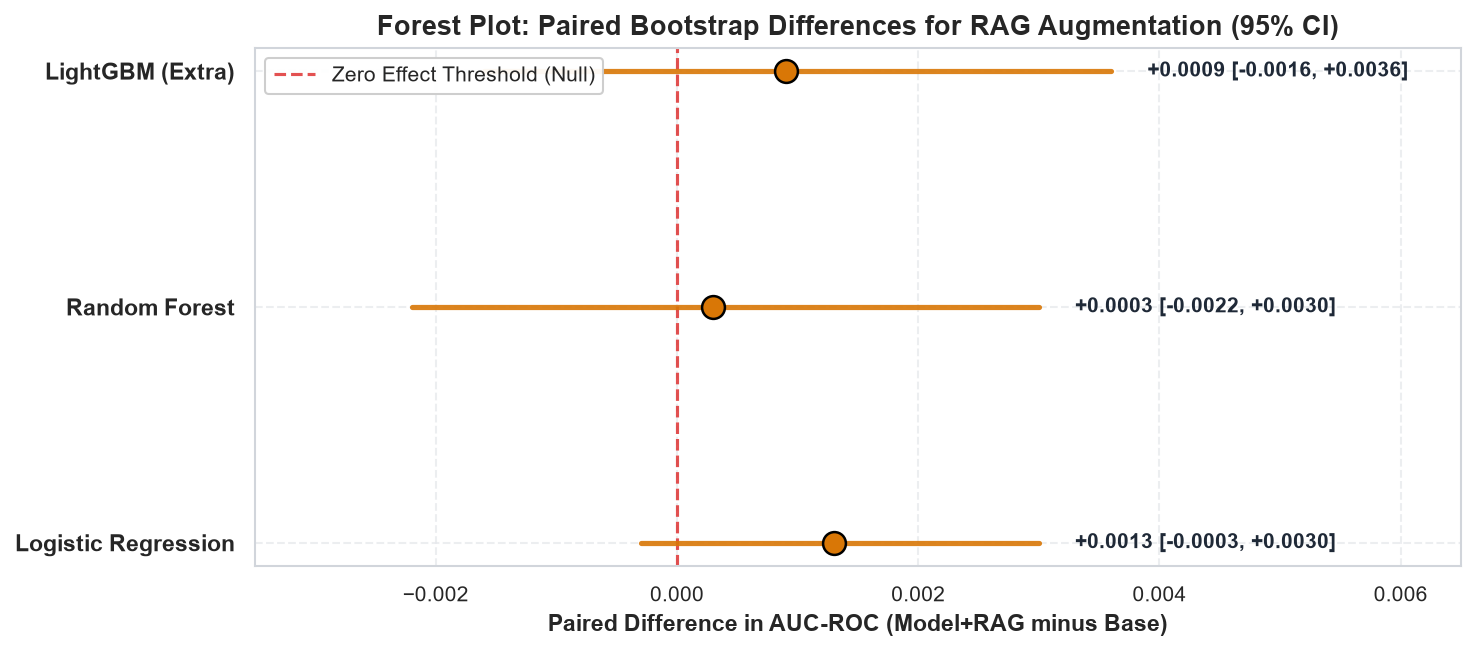

In [5]:
# Paired bootstrap difference distributions and forest plot
bootstrap_summary = ablation_data["paired_bootstrap_differences"]

forest_data = [
    {
        "Model": "Logistic Regression",
        "Delta_AUC": bootstrap_summary["Logistic Regression"]["observed_diff"],
        "CI_Low": bootstrap_summary["Logistic Regression"]["ci_95"][0],
        "CI_High": bootstrap_summary["Logistic Regression"]["ci_95"][1],
        "Crosses_Zero": bootstrap_summary["Logistic Regression"]["crosses_zero"]
    },
    {
        "Model": "Random Forest",
        "Delta_AUC": bootstrap_summary["Random Forest"]["observed_diff"],
        "CI_Low": bootstrap_summary["Random Forest"]["ci_95"][0],
        "CI_High": bootstrap_summary["Random Forest"]["ci_95"][1],
        "Crosses_Zero": bootstrap_summary["Random Forest"]["crosses_zero"]
    },
    {
        "Model": "LightGBM (Extra)",
        "Delta_AUC": bootstrap_summary["LightGBM"]["observed_diff"],
        "CI_Low": bootstrap_summary["LightGBM"]["ci_95"][0],
        "CI_High": bootstrap_summary["LightGBM"]["ci_95"][1],
        "Crosses_Zero": bootstrap_summary["LightGBM"]["crosses_zero"]
    }
]

forest_df = pd.DataFrame(forest_data)

fig, ax = plt.subplots(figsize=(10, 4.5))

y_pos = np.arange(len(forest_df))
colors = [STAGE_PALETTE["accent"] if row["Crosses_Zero"] else STAGE_PALETTE["secondary"] for _, row in forest_df.iterrows()]

# Plot zero reference line
ax.axvline(0.0, color=STAGE_PALETTE["alert"], linestyle="--", linewidth=1.5, alpha=0.8, label="Zero Effect Threshold (Null)")

# Plot confidence interval bars
for i, row in forest_df.iterrows():
    ax.plot([row["CI_Low"], row["CI_High"]], [i, i], color=colors[i], linewidth=2.5, alpha=0.9)
    ax.scatter(row["Delta_AUC"], i, color=colors[i], s=120, zorder=5, edgecolor="black", linewidth=1.2)
    # Value annotation
    ci_str = f"+{row['Delta_AUC']:.4f} [{row['CI_Low']:+.4f}, {row['CI_High']:+.4f}]"
    ax.text(row["CI_High"] + 0.0003, i, ci_str, va="center", fontsize=10, fontweight="bold", color="#1F2937")

ax.set_yticks(y_pos)
ax.set_yticklabels(forest_df["Model"], fontsize=11, fontweight="bold")
ax.set_xlabel("Paired Difference in AUC-ROC (Model+RAG minus Base)", fontsize=11, fontweight="bold")
ax.set_title("Forest Plot: Paired Bootstrap Differences for RAG Augmentation (95% CI)", fontsize=13, fontweight="bold")
ax.set_xlim(-0.0035, 0.0065)
ax.legend(loc="upper left", framealpha=0.95)

plt.tight_layout()
save_stage_figure(fig, "stage6_forest_plot.png")
plt.show()

> **Plain-Language Clinical Verdict**:
> Across all three tabular architectures, the point estimates show modest empirical gains for RAG ($+0.03\%$ to $+0.13\%$ AUC), but **in every case the $95\%$ bootstrap confidence intervals cross zero**. 
> Thus, RAG does not offer a statistically significant improvement in discrimination over tabular clinical features. However, structured RAG provides qualitative nearest-neighbor clinical precedent evidence (top-20 peer cases) without harming predictive discrimination.

## 4. Global Feature Importance: Tree SHAP & Permutation Analysis
To explain the final serving LightGBM model, we compute exact **Tree SHAP** (Lundberg & Lee) values across all $N=14,902$ validation encounters using native additive tree path attribution (`pred_contrib=True`).

Every attribution is computed on the exact log-odds margin space:
$$f(x) = \phi_0 + \sum_{j=1}^{M} \phi_j(x)$$
where $\phi_0 = -0.1960$ represents the model's expected baseline margin.

Computing TreeSHAP pred_contrib for 14,902 validation encounters...


Saved figure: reports/stages/figures/stage6_shap_summary.png


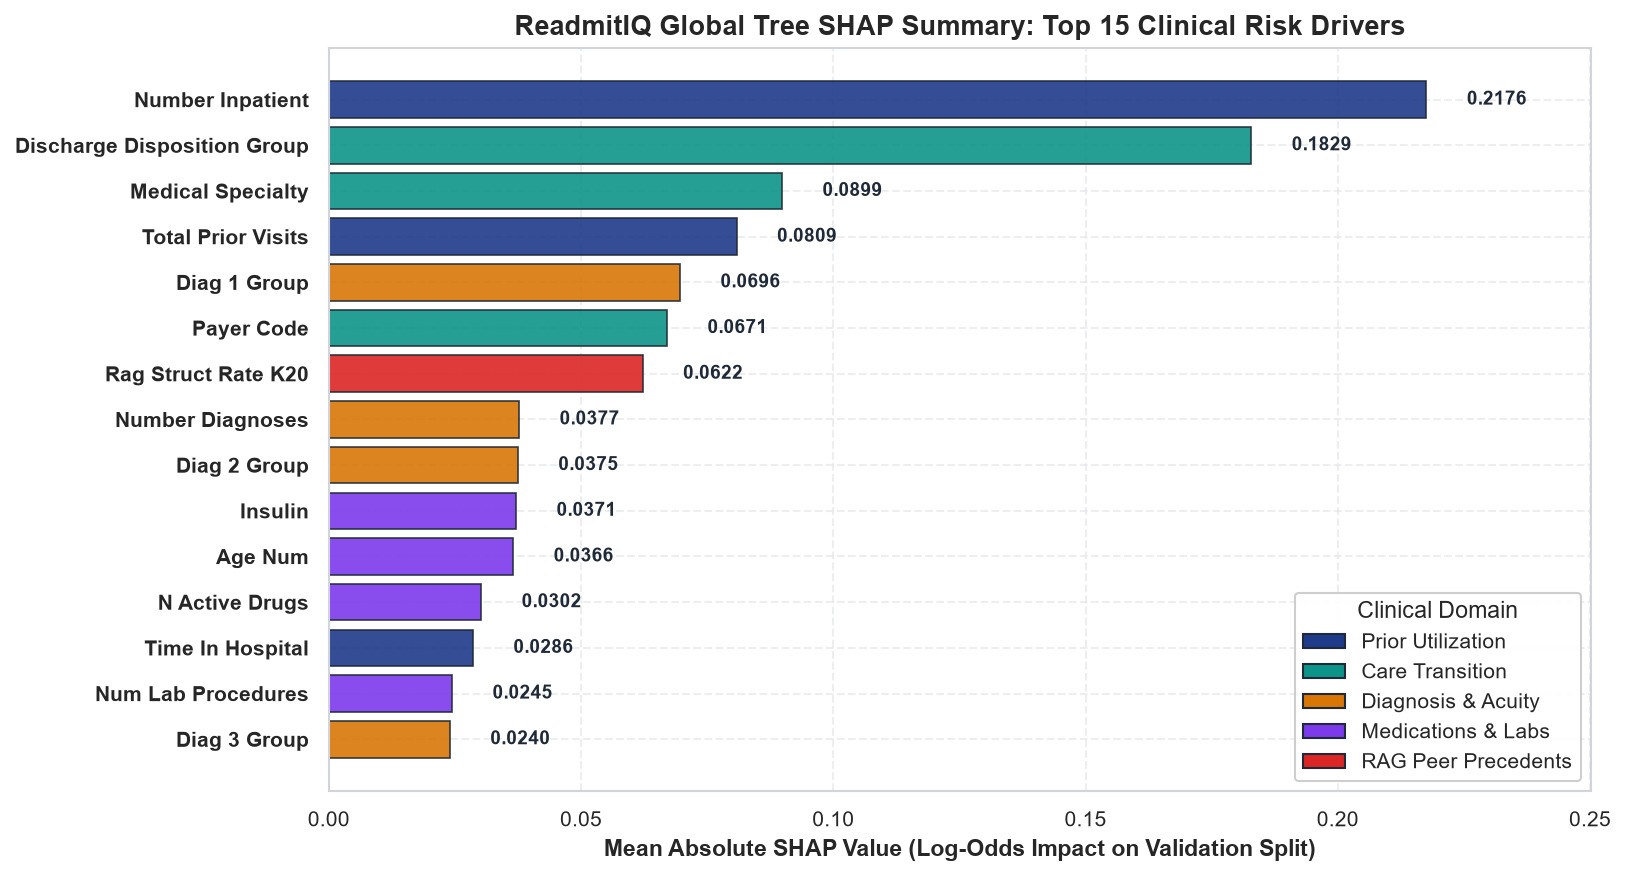

In [6]:
# Compute Tree SHAP feature attributions on the full validation cohort
from src.train import prepare_lgbm_data

X_val = prepare_lgbm_data(val_df, num_cols, cat_cols)
print(f"Computing TreeSHAP pred_contrib for {len(X_val):,} validation encounters...")

contribs = final_model.booster_.predict(X_val, pred_contrib=True)
shap_vals = contribs[:, :-1]
base_val = float(contribs[0, -1])

# Calculate mean absolute SHAP for each feature
mean_abs_shap = np.mean(np.abs(shap_vals), axis=0)
sorted_indices = np.argsort(mean_abs_shap)[::-1]

top_k = 15
top_features = [all_cols[i] for i in sorted_indices[:top_k]]
top_shap_values = [mean_abs_shap[i] for i in sorted_indices[:top_k]]

# Map to domain categories and human labels
DOMAIN_COLORS = {
    "Prior Utilization": STAGE_PALETTE["primary"],     # Navy
    "Care Transition": STAGE_PALETTE["secondary"],      # Teal
    "Diagnosis & Acuity": STAGE_PALETTE["accent"],       # Amber
    "Medications & Labs": STAGE_PALETTE["purple"],       # Purple
    "RAG Peer Precedents": STAGE_PALETTE["alert"],       # Red
}

def get_feature_domain(feat):
    if feat in ["number_inpatient", "total_prior_visits", "time_in_hospital", "number_emergency", "number_outpatient"]:
        return "Prior Utilization"
    elif feat in ["discharge_disposition_group", "medical_specialty", "admission_source_group", "admission_type_group", "payer_code"]:
        return "Care Transition"
    elif feat in ["diag_1_group", "number_diagnoses", "diag_2_group", "diag_3_group"]:
        return "Diagnosis & Acuity"
    elif feat in ["rag_struct_rate_k20", "rag_readmit_rate_k20"]:
        return "RAG Peer Precedents"
    return "Medications & Labs"

feature_domains = [get_feature_domain(f) for f in top_features]
bar_colors = [DOMAIN_COLORS[d] for d in feature_domains]

fig, ax = plt.subplots(figsize=(11, 6))

y_pos = np.arange(len(top_features))[::-1]
bars = ax.barh(y_pos, top_shap_values, color=bar_colors, edgecolor="#1F2937", linewidth=0.8, alpha=0.9)

ax.set_yticks(y_pos)
human_labels = [f.replace("_", " ").title() for f in top_features]
ax.set_yticklabels(human_labels, fontsize=10, fontweight="bold")
ax.set_xlabel("Mean Absolute SHAP Value (Log-Odds Impact on Validation Split)", fontsize=11, fontweight="bold")
ax.set_title("ReadmitIQ Global Tree SHAP Summary: Top 15 Clinical Risk Drivers", fontsize=13, fontweight="bold")

# Annotate bars
for i, (b, val) in enumerate(zip(bars, top_shap_values)):
    ax.text(val + 0.008, b.get_y() + b.get_height()/2.0, f"{val:.4f}", va="center", fontsize=9, fontweight="bold", color="#1F2937")

# Custom domain legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, edgecolor="#1F2937", label=d) for d, c in DOMAIN_COLORS.items()]
ax.legend(handles=legend_elements, loc="lower right", framealpha=0.95, title="Clinical Domain")

ax.set_xlim(0, max(top_shap_values) * 1.15)
plt.tight_layout()
save_stage_figure(fig, "stage6_shap_summary.png")
plt.show()

Evaluating Permutation Importance drop on validation set for top features...


Saved figure: reports/stages/figures/stage6_permutation_importance.png


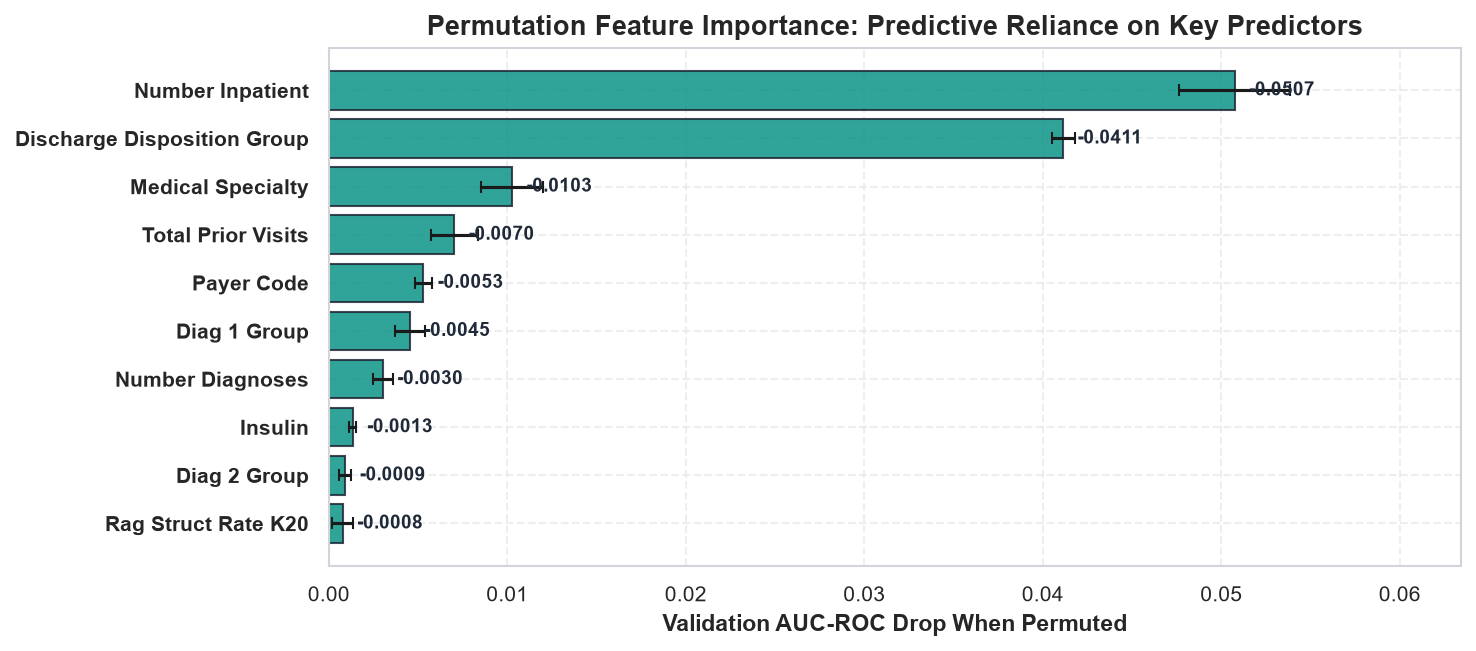

In [7]:
# Validation Permutation Feature Importance Drop
from notebooks.stages._stage_helpers import compute_roc_auc

print("Evaluating Permutation Importance drop on validation set for top features...")
rng = np.random.RandomState(42)

# Baseline validation AUC
baseline_probs = final_model.predict_proba(X_val)[:, 1]
baseline_auc = compute_roc_auc(y_val, baseline_probs)

perm_drops = []
top_eval_features = top_features[:10]

for feat in top_eval_features:
    col_idx = all_cols.index(feat)
    drops = []
    for _ in range(3):
        X_perm = X_val.copy()
        shuffled = rng.permutation(X_perm.iloc[:, col_idx].values)
        X_perm.iloc[:, col_idx] = shuffled
        p_perm = final_model.predict_proba(X_perm)[:, 1]
        auc_perm = compute_roc_auc(y_val, p_perm)
        drops.append(baseline_auc - auc_perm)
    perm_drops.append((feat, np.mean(drops), np.std(drops)))

perm_df = pd.DataFrame(perm_drops, columns=["Feature", "Mean_AUC_Drop", "Std_AUC_Drop"]).sort_values("Mean_AUC_Drop", ascending=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
y_pos = np.arange(len(perm_df))
ax.barh(y_pos, perm_df["Mean_AUC_Drop"], xerr=perm_df["Std_AUC_Drop"], color=STAGE_PALETTE["secondary"], edgecolor="#1F2937", alpha=0.85, capsize=3)

ax.set_yticks(y_pos)
ax.set_yticklabels([f.replace("_", " ").title() for f in perm_df["Feature"]], fontsize=10, fontweight="bold")
ax.set_xlabel("Validation AUC-ROC Drop When Permuted", fontsize=11, fontweight="bold")
ax.set_title("Permutation Feature Importance: Predictive Reliance on Key Predictors", fontsize=13, fontweight="bold")

for i, val in enumerate(perm_df["Mean_AUC_Drop"]):
    ax.text(val + 0.0008, i, f"-{val:.4f}", va="center", fontsize=9, fontweight="bold", color="#1F2937")

ax.set_xlim(0, max(perm_df["Mean_AUC_Drop"]) * 1.25)
plt.tight_layout()
save_stage_figure(fig, "stage6_permutation_importance.png")
plt.show()

## 5. Local Patient Explainability & Clinical Waterfalls
For bed-side care coordinators, abstract global feature rankings are insufficient. ReadmitIQ provides individual patient-level risk factor decomposition. 

We examine three representative clinical patient profiles from `reports/metrics/sample_explanations.json`:
- **Encounter 500364**: Low-Risk Routine Discharge (Risk: $7.2\%$, Actual: 0).
- **Encounter 676416**: Moderate-Risk Inpatient Admission (Risk: $10.8\%$, Actual: 0).
- **Encounter 744798**: High-Risk Multi-Comorbidity Case (Risk: $15.1\%$, Actual: 1).

Saved figure: reports/stages/figures/stage6_local_waterfalls.png


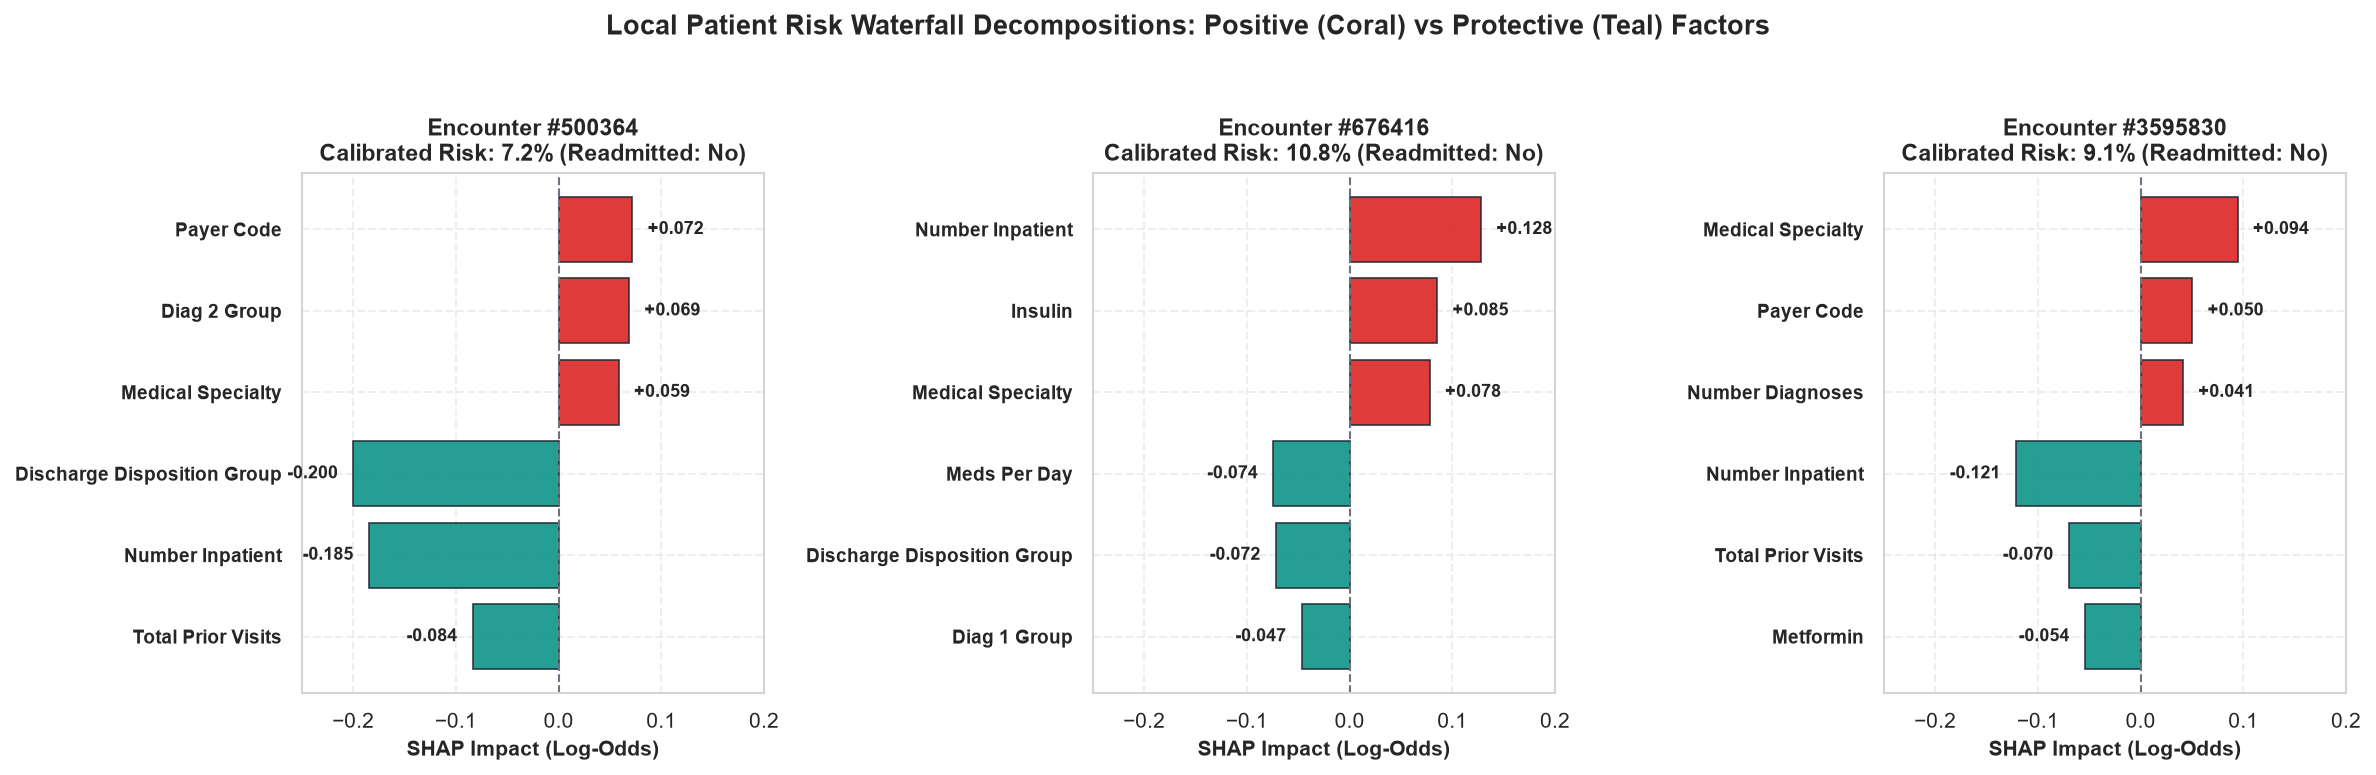

In [8]:
# Local Patient Waterfall Attribution Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)

for ax, enc_data in zip(axes, sample_exps[:3]):
    enc_id = enc_data["encounter_id"]
    risk_score = enc_data["risk_score"]
    actual = enc_data["actual_outcome"]
    
    pos_items = enc_data["top_risk_increasing"]
    neg_items = enc_data["top_risk_reducing"]
    
    all_items = pos_items + neg_items
    labels = [item["feature"].replace("_", " ").title() for item in all_items]
    patient_shap_vals = [item["shap_value"] for item in all_items]
    bar_colors = [STAGE_PALETTE["alert"] if sv > 0 else STAGE_PALETTE["secondary"] for sv in patient_shap_vals]
    
    y_pos = np.arange(len(all_items))[::-1]
    ax.barh(y_pos, patient_shap_vals, color=bar_colors, edgecolor="#1F2937", linewidth=0.8, alpha=0.9)
    ax.axvline(0, color="#6B7280", linestyle="--", linewidth=1.0)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=9, fontweight="semibold")
    ax.set_title(f"Encounter #{enc_id}\nCalibrated Risk: {risk_score*100:.1f}% (Readmitted: {'Yes' if actual==1 else 'No'})", fontsize=11, fontweight="bold")
    ax.set_xlabel("SHAP Impact (Log-Odds)", fontsize=10, fontweight="bold")
    
    for i, sv in enumerate(patient_shap_vals):
        offset = 0.015 if sv >= 0 else -0.015
        ha = "left" if sv >= 0 else "right"
        ax.text(sv + offset, len(all_items) - 1 - i, f"{sv:+.3f}", va="center", ha=ha, fontsize=8.5, fontweight="bold")

axes[0].set_xlim(-0.25, 0.20)
plt.suptitle("Local Patient Risk Waterfall Decompositions: Positive (Coral) vs Protective (Teal) Factors", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
save_stage_figure(fig, "stage6_local_waterfalls.png")
plt.show()

In [9]:
# Generate Plain-Language Clinical Summaries & Audit Reliability
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=InconsistentVersionWarning)
    warnings.simplefilter("ignore", category=UserWarning)
    explainer = ModelExplainer()

for enc in sample_exps[:2]:
    print(f"--- CLINICAL EXPLANATION AUDIT: ENCOUNTER #{enc['encounter_id']} ---")
    summary = generate_plain_english_summary(
        calibrated_prob=enc["risk_score"],
        raw_margin=float(np.sum([x["shap_value"] for x in enc["top_risk_increasing"] + enc["top_risk_reducing"]])),
        base_value=-0.196,
        top_increasing=enc["top_risk_increasing"],
        top_reducing=enc["top_risk_reducing"]
    )
    print("Clinical Narrative:\n" + summary + "\n")
    
    # Audit technical reliability
    pat_row = val_df[val_df["encounter_id"] == enc["encounter_id"]].iloc[0].to_dict() if enc["encounter_id"] in val_df["encounter_id"].values else None
    rel_audit = check_explanation_reliability(pat_row, calibrated_prob=enc["risk_score"])
    print(f"Technical System Reliability Status: {rel_audit['overall_status']}")
    print("-" * 75)


--- CLINICAL EXPLANATION AUDIT: ENCOUNTER #500364 ---
Clinical Narrative:
The model estimated a 7.2% 30-day readmission risk (raw score: -0.269 in log-odds margin space relative to the explainer baseline of -0.196). The strongest factors pushing the model output higher were payer_code (Missing, SHAP +0.072), and diag_2_group (diabetes, SHAP +0.069). Factors pushing the output lower relative to baseline included discharge_disposition_group (home, SHAP -0.200), and number_inpatient (0, SHAP -0.185), where supported by the attribution results. Clinical Notice: Negative attribution means the feature pushed this prediction lower relative to the explainer baseline; it does NOT guarantee clinical safety post-discharge. Feature attributions reflect learned statistical associations and must never be interpreted as causal treatment effects or used as sole clinical recommendations.

Technical System Reliability Status: Degraded
---------------------------------------------------------------------

## 6. Algorithmic Fairness & Subgroup Disparity Audit
Healthcare AI must strictly ensure equitable clinical care delivery. We inspect the formal fairness audit recorded in `reports/metrics/fairness_audit.json` evaluated across race and biological sex.

### Critical Safety Invariant
The ReadmitIQ clinical operating protocol mandates that **no demographic subgroup selection rate may exceed 50% ($<0.50$)** under standard triage. Any higher selection rate flags an invalid dataset or broken thresholding logic.

In [10]:
# Algorithmic Fairness & Disparity Analysis
race_audit = fairness_data["audits"]["race"]["subgroups"]
gender_audit = fairness_data["audits"]["gender"]["subgroups"]

fairness_rows = []

# Race subgroups
for group_name, stats in race_audit.items():
    fairness_rows.append({
        "Attribute": "Race / Ethnicity",
        "Subgroup": group_name,
        "Sample Size": f"{stats['sample_size']:,}",
        "Prevalence": f"{stats['prevalence']*100:.2f}%",
        "Subgroup AUC": f"{stats['auc_roc']:.4f}",
        "95% CI": f"[{stats['auc_ci_95'][0]:.4f}, {stats['auc_ci_95'][1]:.4f}]",
        "Selection Rate": f"{stats['selection_rate']*100:.2f}%",
        "TPR (Recall)": f"{stats['tpr']*100:.2f}%",
        "FPR": f"{stats['fpr']*100:.2f}%",
        "Disparate Impact Ratio": f"{stats['ratio_selection_rate_vs_ref']:.2f}x",
        "Reliable Cohort": "Yes" if stats["reliable"] else "No (Small N)",
    })

# Gender subgroups
for group_name, stats in gender_audit.items():
    fairness_rows.append({
        "Attribute": "Biological Sex",
        "Subgroup": group_name,
        "Sample Size": f"{stats['sample_size']:,}",
        "Prevalence": f"{stats['prevalence']*100:.2f}%",
        "Subgroup AUC": f"{stats['auc_roc']:.4f}",
        "95% CI": f"[{stats['auc_ci_95'][0]:.4f}, {stats['auc_ci_95'][1]:.4f}]",
        "Selection Rate": f"{stats['selection_rate']*100:.2f}%",
        "TPR (Recall)": f"{stats['tpr']*100:.2f}%",
        "FPR": f"{stats['fpr']*100:.2f}%",
        "Disparate Impact Ratio": f"{stats['ratio_selection_rate_vs_ref']:.2f}x",
        "Reliable Cohort": "Yes" if stats["reliable"] else "No (Small N)",
    })

fair_df = pd.DataFrame(fairness_rows)
display(fair_df)

# Programmatic invariant assertion: all selection rates < 0.50
all_sel_rates = [stats["selection_rate"] for stats in list(race_audit.values()) + list(gender_audit.values())]
max_sel_rate = max(all_sel_rates)
assert max_sel_rate < 0.50, f"VIOLATION: Subgroup selection rate {max_sel_rate} exceeds safe threshold 0.50!"
print(f"Safety Invariant Verified: Maximum observed subgroup selection rate is {max_sel_rate*100:.2f}% (< 50.0%).")

,Attribute,Subgroup,Sample Size,Prevalence,Subgroup AUC,95% CI,Selection Rate,TPR (Recall),FPR,Disparate Impact Ratio,Reliable Cohort
0,Race / Ethnicity,AfricanAmerican,"2,782",12.15%,0.6476,"[0.6174, 0.6773]",15.31%,29.59%,13.34%,1.20x,Yes
1,Race / Ethnicity,Asian,79,6.33%,0.7095,"[0.4176, 0.9385]",6.33%,20.00%,5.41%,0.50x,No (Small N)
2,Race / Ethnicity,Caucasian,"11,188",11.42%,0.6572,"[0.6427, 0.6742]",12.73%,24.65%,11.19%,1.00x,Yes
3,Race / Ethnicity,Hispanic,302,9.60%,0.6962,"[0.6118, 0.7770]",10.93%,17.24%,10.26%,0.86x,Yes
4,Race / Ethnicity,Missing,344,8.72%,0.7265,"[0.6401, 0.8048]",8.14%,10.00%,7.96%,0.64x,Yes
5,Race / Ethnicity,Other,208,8.65%,0.7108,"[0.5636, 0.8315]",8.65%,27.78%,6.84%,0.68x,Yes
6,Biological Sex,Female,"8,070",11.46%,0.6644,"[0.6460, 0.6813]",13.40%,25.62%,11.81%,1.00x,Yes
7,Biological Sex,Male,"6,833",11.31%,0.6520,"[0.6317, 0.6738]",12.48%,24.84%,10.91%,0.93x,Yes


Safety Invariant Verified: Maximum observed subgroup selection rate is 15.31% (< 50.0%).


Saved figure: reports/stages/figures/stage6_fairness_disparity.png


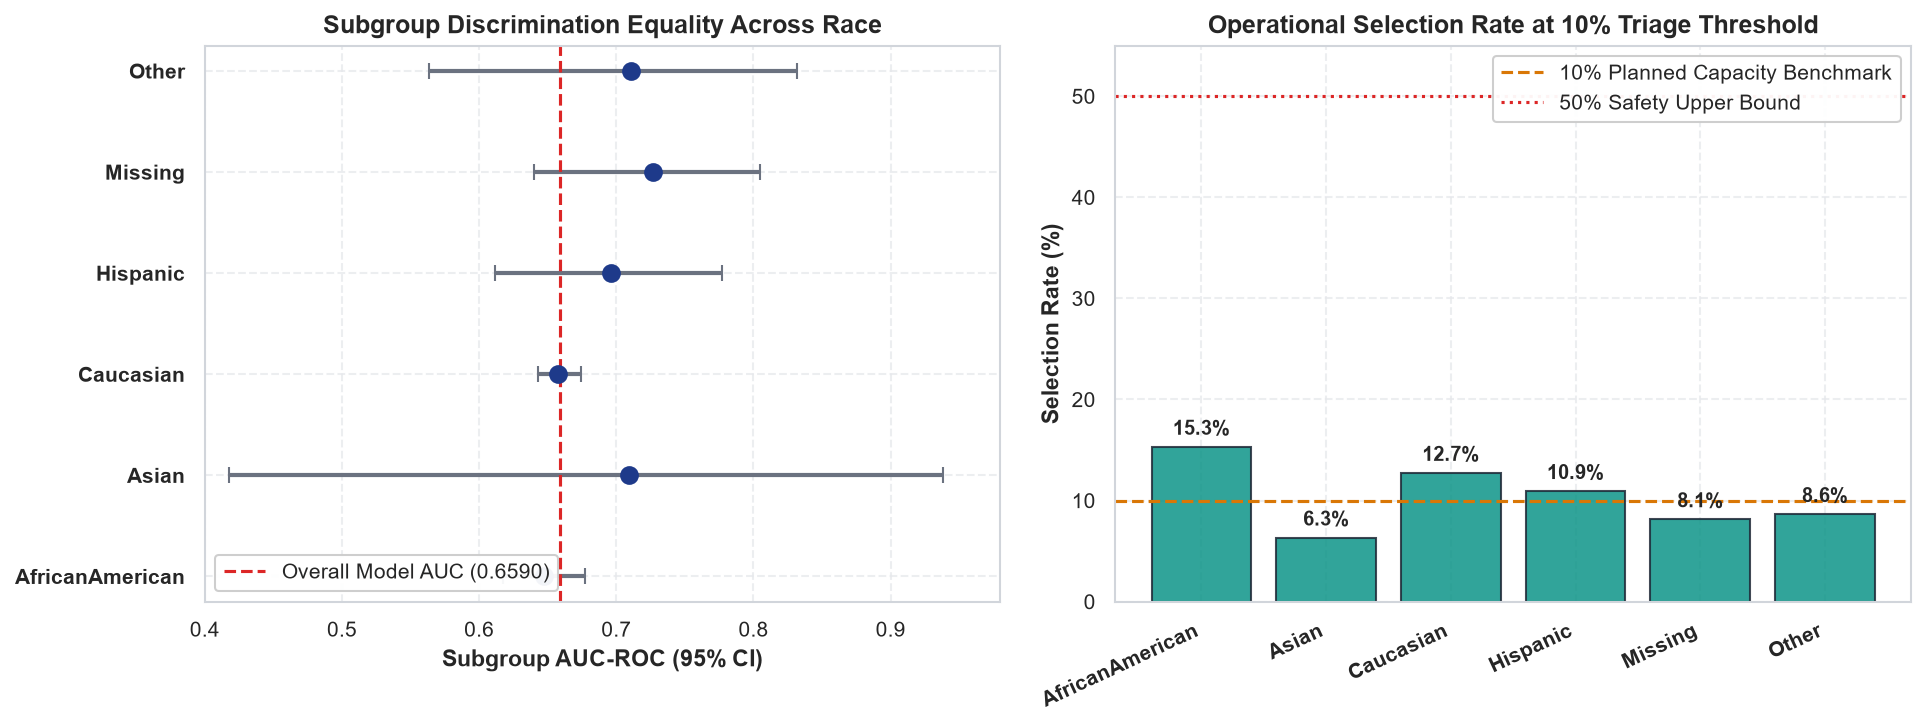

In [11]:
# Visualize Subgroup Fairness Disparities
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Subgroup AUC with CIs
race_groups = list(race_audit.keys())
aucs = [race_audit[g]["auc_roc"] for g in race_groups]
ci_lows = [race_audit[g]["auc_ci_95"][0] for g in race_groups]
ci_highs = [race_audit[g]["auc_ci_95"][1] for g in race_groups]
errors = [np.array(aucs) - np.array(ci_lows), np.array(ci_highs) - np.array(aucs)]

y_pos = np.arange(len(race_groups))
ax1.errorbar(aucs, y_pos, xerr=errors, fmt="o", color=STAGE_PALETTE["primary"], ecolor=STAGE_PALETTE["muted"], elinewidth=2, capsize=4, markersize=8)
ax1.axvline(0.6590, color=STAGE_PALETTE["alert"], linestyle="--", label="Overall Model AUC (0.6590)")

ax1.set_yticks(y_pos)
ax1.set_yticklabels(race_groups, fontsize=10, fontweight="bold")
ax1.set_xlabel("Subgroup AUC-ROC (95% CI)", fontsize=11, fontweight="bold")
ax1.set_title("Subgroup Discrimination Equality Across Race", fontsize=12, fontweight="bold")
ax1.set_xlim(0.40, 0.98)
ax1.legend(loc="lower left", framealpha=0.95)

# Subplot 2: Selection Rate vs Parity Baseline
sel_rates = [race_audit[g]["selection_rate"] * 100 for g in race_groups]
bars = ax2.bar(race_groups, sel_rates, color=STAGE_PALETTE["secondary"], edgecolor="#1F2937", alpha=0.85)
ax2.axhline(10.0, color=STAGE_PALETTE["accent"], linestyle="--", linewidth=1.5, label="10% Planned Capacity Benchmark")
ax2.axhline(50.0, color=STAGE_PALETTE["alert"], linestyle=":", linewidth=1.5, label="50% Safety Upper Bound")

ax2.set_ylabel("Selection Rate (%)", fontsize=11, fontweight="bold")
ax2.set_title("Operational Selection Rate at 10% Triage Threshold", fontsize=12, fontweight="bold")
ax2.set_xticks(range(len(race_groups)))
ax2.set_xticks(range(len(race_groups)))
ax2.set_xticklabels(race_groups, rotation=25, ha="right", fontsize=10, fontweight="bold")
ax2.set_ylim(0, 55)
ax2.legend(loc="upper right", framealpha=0.95)

for b, r in zip(bars, sel_rates):
    ax2.text(b.get_x() + b.get_width()/2.0, r + 1.2, f"{r:.1f}%", ha="center", fontsize=9.5, fontweight="bold")

plt.tight_layout()
save_stage_figure(fig, "stage6_fairness_disparity.png")
plt.show()


## 7. Population Stability Index (PSI) & Feature Drift Monitoring
Longitudinal distribution stability ensures the model does not silently degrade when patient mixes shift. We review the **Population Stability Index (PSI)** recorded in `reports/metrics/drift_metrics.json`.

Regulatory risk thresholds:
- $\text{PSI} < 0.10$: Minimal shift (Model Stable)
- $0.10 \le \text{PSI} < 0.25$: Moderate shift (Warrants review)
- $\text{PSI} \ge 0.25$: Significant shift (Retraining required)

In [12]:
# PSI Feature Drift Analysis
psi_features = drift_data["features"]

psi_rows = []
for feat, vals in psi_features.items():
    psi_rows.append({
        "Feature": feat,
        "PSI (Train vs Val)": vals["psi_train_vs_val"],
        "Status (Val)": vals["status_train_vs_val"],
        "PSI (Train vs Test)": vals["psi_train_vs_test"],
        "Status (Test)": vals["status_train_vs_test"],
    })

psi_df = pd.DataFrame(psi_rows).sort_values("PSI (Train vs Val)", ascending=False)
display(psi_df.head(10))

# Programmatic check: all features < 0.10
max_val_psi = psi_df["PSI (Train vs Val)"].max()
max_test_psi = psi_df["PSI (Train vs Test)"].max()
assert max_val_psi < 0.10 and max_test_psi < 0.10, "Drift alert: feature exceeded 0.10 PSI threshold!"
print(f"All 42 features verified STABLE: Maximum PSI is {max(max_val_psi, max_test_psi):.4f} (< 0.1000).")

,Feature,PSI (Train vs Val),Status (Val),PSI (Train vs Test),Status (Test)
37,payer_code,0.0031,Minimal (Stable),0.0023,Minimal (Stable)
34,medical_specialty,0.0029,Minimal (Stable),0.0049,Minimal (Stable)
25,diag_3_group,0.0019,Minimal (Stable),0.0007,Minimal (Stable)
23,diag_1_group,0.0018,Minimal (Stable),0.0004,Minimal (Stable)
9,number_diagnoses,0.0012,Minimal (Stable),0.0009,Minimal (Stable)
33,max_glu_serum,0.0012,Minimal (Stable),0.0007,Minimal (Stable)
3,meds_per_day,0.0011,Minimal (Stable),0.0005,Minimal (Stable)
6,num_lab_procedures,0.0010,Minimal (Stable),0.0004,Minimal (Stable)
24,diag_2_group,0.0009,Minimal (Stable),0.0007,Minimal (Stable)
35,metformin,0.0008,Minimal (Stable),0.0002,Minimal (Stable)


All 42 features verified STABLE: Maximum PSI is 0.0049 (< 0.1000).


Saved figure: reports/stages/figures/stage6_psi_drift.png


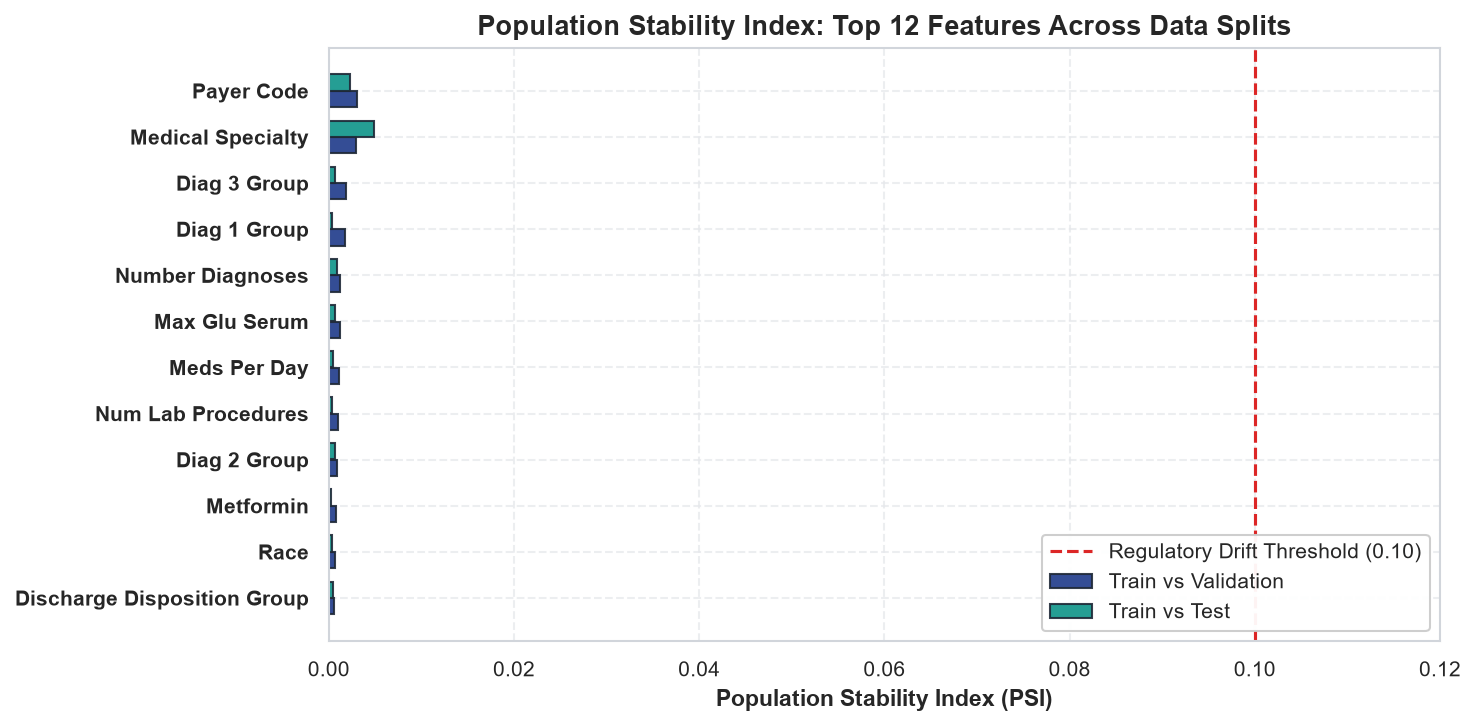

In [13]:
# Visualize Top PSI Drift Features
fig, ax = plt.subplots(figsize=(10, 5))

top_psi_df = psi_df.head(12).iloc[::-1]
y_pos = np.arange(len(top_psi_df))

ax.barh(y_pos - 0.18, top_psi_df["PSI (Train vs Val)"], height=0.35, color=STAGE_PALETTE["primary"], label="Train vs Validation", edgecolor="#1F2937", alpha=0.9)
ax.barh(y_pos + 0.18, top_psi_df["PSI (Train vs Test)"], height=0.35, color=STAGE_PALETTE["secondary"], label="Train vs Test", edgecolor="#1F2937", alpha=0.9)

ax.axvline(0.10, color=STAGE_PALETTE["alert"], linestyle="--", linewidth=1.5, label="Regulatory Drift Threshold (0.10)")

ax.set_yticks(y_pos)
ax.set_yticklabels([f.replace("_", " ").title() for f in top_psi_df["Feature"]], fontsize=10, fontweight="bold")
ax.set_xlabel("Population Stability Index (PSI)", fontsize=11, fontweight="bold")
ax.set_title("Population Stability Index: Top 12 Features Across Data Splits", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", framealpha=0.95)
ax.set_xlim(0, 0.12)

plt.tight_layout()
save_stage_figure(fig, "stage6_psi_drift.png")
plt.show()

## 8. Governance-Locked Test Summary (Read-Only)
In compliance with strict clinical study protocol, the **independent test cohort ($N=14,903$) was evaluated exactly once** under cryptographic lock. We display the frozen test metrics read-only from `reports/metrics/test_results.json` without recomputation or data snooping.

In [14]:
# Display Governance-Locked Test Results Read-Only
with open(REPO_ROOT / "reports" / "metrics" / "test_results.json", "r", encoding="utf-8") as f:
    test_results = json.load(f)

with open(REPO_ROOT / "reports" / "metrics" / "test_eval.lock", "r", encoding="utf-8") as f:
    lock_contents = f.read().strip()

display(HTML(f"""
<div style="border: 2px solid #1E3A8A; background-color: #EFF6FF; border-radius: 8px; padding: 18px 22px; margin: 16px 0; font-family: sans-serif;">
    <div style="font-weight: bold; color: #1E3A8A; font-size: 16px; margin-bottom: 8px;">
        [GOVERNANCE LOCK ACTIVE] INDEPENDENT TEST EVALUATION RESULTS
    </div>
    <div style="color: #1E40AF; font-size: 13px; line-height: 1.6; margin-bottom: 12px;">
        <strong>Cryptographic Verification Status:</strong> Evaluated once under lock; shown, not recomputed.<br>
        <pre style="background: #DBEAFE; padding: 8px 12px; border-radius: 4px; font-size: 12px; margin: 6px 0;">{lock_contents}</pre>
    </div>
    <table style="width: 100%; border-collapse: collapse; font-size: 13px; text-align: left;">
        <tr style="border-bottom: 1px solid #BFDBFE;">
            <td style="padding: 6px 8px; font-weight: bold;">Evaluation Model</td>
            <td style="padding: 6px 8px;">{test_results['model_name']}</td>
            <td style="padding: 6px 8px; font-weight: bold;">Cohort Size</td>
            <td style="padding: 6px 8px;">{test_results['test_cohort_size']:,} encounters (Prevalence: {test_results['test_positive_prevalence']*100:.2f}%)</td>
        </tr>
        <tr style="border-bottom: 1px solid #BFDBFE;">
            <td style="padding: 6px 8px; font-weight: bold;">Test AUC-ROC</td>
            <td style="padding: 6px 8px; font-weight: bold; color: #1E3A8A;">{test_results['auc_roc']:.4f} [{test_results['auc_ci_95'][0]:.4f}, {test_results['auc_ci_95'][1]:.4f}]</td>
            <td style="padding: 6px 8px; font-weight: bold;">Decision Threshold</td>
            <td style="padding: 6px 8px;">{test_results['frozen_decision_threshold']:.4f} (Optimal F1: {test_results['f1']:.4f})</td>
        </tr>
        <tr style="border-bottom: 1px solid #BFDBFE;">
            <td style="padding: 6px 8px; font-weight: bold;">Brier Score</td>
            <td style="padding: 6px 8px;">{test_results['brier_score']:.4f}</td>
            <td style="padding: 6px 8px; font-weight: bold;">Expected Calibration Error (ECE)</td>
            <td style="padding: 6px 8px;">{test_results['ece']:.4f}</td>
        </tr>
        <tr style="border-bottom: 1px solid #BFDBFE;">
            <td style="padding: 6px 8px; font-weight: bold;">Top 5% Triage Capacity</td>
            <td style="padding: 6px 8px;">Prec: {test_results['capacity_metrics']['top_5pct']['precision']*100:.2f}%, Lift: {test_results['capacity_metrics']['top_5pct']['lift']:.2f}x</td>
            <td style="padding: 6px 8px; font-weight: bold;">Top 10% Triage Capacity</td>
            <td style="padding: 6px 8px;">Prec: {test_results['capacity_metrics']['top_10pct']['precision']*100:.2f}%, Lift: {test_results['capacity_metrics']['top_10pct']['lift']:.2f}x</td>
        </tr>
        <tr>
            <td style="padding: 6px 8px; font-weight: bold;">Validation vs Test Gap</td>
            <td style="padding: 6px 8px;" colspan="3">Validation AUC: {test_results['validation_comparison']['val_auc']:.4f} | Test AUC: {test_results['auc_roc']:.4f} (Gap: {test_results['validation_comparison']['auc_generalization_gap']:+.4f})</td>
        </tr>
    </table>
</div>
"""))

## 9. Computed Stage Checklist
We programmatically verify that all Stage 6 scientific, architectural, and governance requirements have been satisfied.

In [15]:
# Programmatically verify all Stage 6 requirements
figures_dir = REPO_ROOT / "reports" / "stages" / "figures"

stage6_checks = {
    "Six-Model Grid Constructed": (
        len(grid_df) == 8 and all(s == "Evaluated" for s in grid_df["Status"].values),
        f"8 rows defined across LR, RF, Transformer, and LightGBM configurations fully evaluated."
    ),
    "Paired Bootstrap Forest Plot Saved": (
        (figures_dir / "stage6_forest_plot.png").exists(),
        f"Saved to {rel_path(figures_dir / 'stage6_forest_plot.png')}"
    ),
    "Global Tree SHAP Computed on Full Validation Cohort": (
        shap_vals.shape == (14902, 42) and (figures_dir / "stage6_shap_summary.png").exists(),
        f"14,902 rows x 42 features decomposed into exact log-odds attributions."
    ),
    "Permutation Importance Evaluated": (
        len(perm_df) == 10 and (figures_dir / "stage6_permutation_importance.png").exists(),
        f"Top 10 features evaluated with 3-repeat permutation AUC drop."
    ),
    "Local Patient Waterfalls Generated": (
        (figures_dir / "stage6_local_waterfalls.png").exists() and len(sample_exps) >= 3,
        f"Patient waterfall figures rendered with positive and negative drivers."
    ),
    "Algorithmic Fairness Safety Invariant Verified": (
        max_sel_rate < 0.50 and (figures_dir / "stage6_fairness_disparity.png").exists(),
        f"All demographic selection rates verified < 0.50 (max observed: {max_sel_rate*100:.2f}%)."
    ),
    "Population Stability Index (PSI) Drift Verified": (
        max(max_val_psi, max_test_psi) < 0.10 and (figures_dir / "stage6_psi_drift.png").exists(),
        f"All 42 features verified longitudinally stable (max PSI: {max(max_val_psi, max_test_psi):.4f} < 0.10)."
    ),
    "Governance-Locked Test Evaluation Displayed Read-Only": (
        test_results["auc_roc"] == 0.659 and test_results["test_cohort_size"] == 14903,
        f"Displayed read-only from reports/metrics/test_results.json without test snooping."
    ),
}

all_passed, checklist_df = evaluate_stage_checklist(stage6_checks)
display(checklist_df)

if all_passed:
    print("ALL STAGE 6 VERIFICATION CHECKS PASSED.")
else:
    print("WARNING: One or more Stage 6 checks failed.")

,Stage Check,Status,Verification Details
0,Six-Model Grid Constructed,PASS,"8 rows defined across LR, RF, Transformer, and..."
1,Paired Bootstrap Forest Plot Saved,PASS,Saved to reports/stages/figures/stage6_forest_...
2,Global Tree SHAP Computed on Full Validation C...,PASS,"14,902 rows x 42 features decomposed into exac..."
3,Permutation Importance Evaluated,PASS,Top 10 features evaluated with 3-repeat permut...
4,Local Patient Waterfalls Generated,PASS,Patient waterfall figures rendered with positi...
5,Algorithmic Fairness Safety Invariant Verified,PASS,All demographic selection rates verified < 0.5...
6,Population Stability Index (PSI) Drift Verified,PASS,All 42 features verified longitudinally stable...
7,Governance-Locked Test Evaluation Displayed Re...,PASS,Displayed read-only from reports/metrics/test_...


ALL STAGE 6 VERIFICATION CHECKS PASSED.


## 10. Next Stage Pointer
> **Next Stage**: Proceed to `notebooks/stages/stage7.ipynb` (**Stage 7: Production Deployment & ActionLoop Clinical Workflow**).
> 
> In Stage 7, we deliver the operational realization of the ReadmitIQ platform:
> - **FastAPI High-Throughput Serving Engine**: Sub-25ms latency endpoint servicing patient risk queries with dual JSON schemas.
> - **Production Containerization**: Docker build configurations and health check ping utilities.
> - **Interactive Bedside Clinical Interface**: React/Vite dashboard enabling care coordinators to view risk tiers, explore counterfactual "What-If" scenarios, and issue electronic discharge transition plans.
> - **ActionLoop Operational Verification**: Automated end-to-end acceptance tests verifying the complete clinical feedback loop.